In [1]:
import polars as pl, duckdb, plotly.express as px, os
os.makedirs("../output/figures", exist_ok=True)
P = "../data/processed/data_clean.parquet"
lf = pl.scan_parquet(P)
schema = lf.collect_schema()

def save(fig, name):
    fig.write_html(f"../output/figures/{name}.html"); fig.show()

DATE_COL = next((c for c, t in schema.items() if isinstance(t, pl.Datetime)), None)
NUM_COLS = [c for c, t in schema.items() if t == pl.Float64 and not c.startswith("out_")]
str_cols = [c for c, t in schema.items() if t == pl.String]
nu = lf.select([pl.col(c).n_unique().alias(c) for c in str_cols]).collect().row(0, named=True) if str_cols else {}
CAT_COLS = [c for c in str_cols if 2 <= nu[c] <= 200]

low = {c: c.lower() for c in schema.names()}
LAT = next((c for c, l in low.items() if l in ("lat", "latitude")), None)
LON = next((c for c, l in low.items() if l in ("lon", "lng", "long", "longitude")), None)
GEO = next((c for c in CAT_COLS if any(h in low[c] for h in
           ("prov", "kota", "kab", "wilayah", "lokasi", "region", "city", "kec", "daerah"))), None)

print("DATE:", DATE_COL, "| NUM:", NUM_COLS, "| CAT:", CAT_COLS, "| LAT/LON:", LAT, LON, "| GEO:", GEO)
N1 = NUM_COLS[0] if NUM_COLS else None
C1 = CAT_COLS[0] if CAT_COLS else None
C2 = GEO or (CAT_COLS[1] if len(CAT_COLS) > 1 else C1)

DATE: date | NUM: ['id'] | CAT: ['source'] | LAT/LON: None None | GEO: None


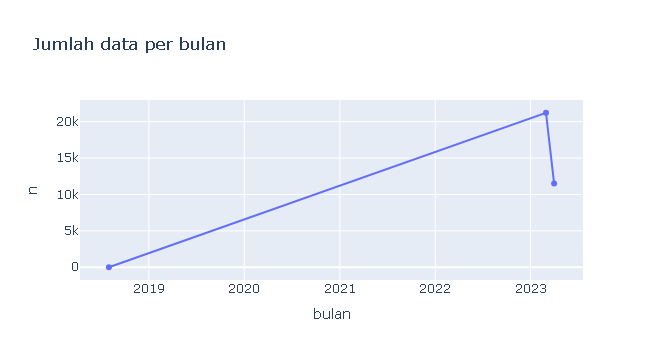

In [2]:
if DATE_COL:
    d = duckdb.sql(f"""SELECT date_trunc('month', "{DATE_COL}") AS bulan, count(*) AS n
                       FROM '{P}' WHERE "{DATE_COL}" IS NOT NULL GROUP BY 1 ORDER BY 1""").pl()
    save(px.line(d, x="bulan", y="n", markers=True, title="Jumlah data per bulan"), "01_tren_bulanan")

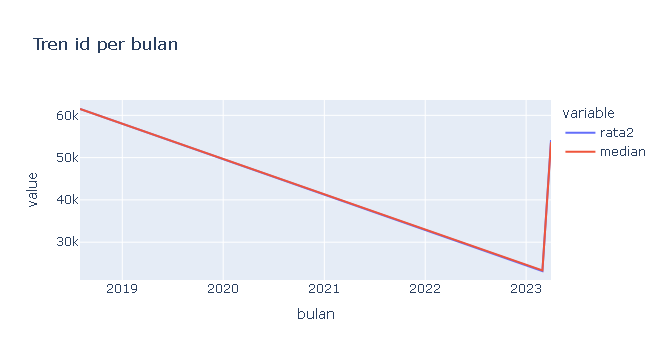

In [3]:
if DATE_COL and N1:
    m = duckdb.sql(f"""SELECT date_trunc('month', "{DATE_COL}") AS bulan,
                              avg("{N1}") AS rata2, median("{N1}") AS median
                       FROM '{P}' WHERE "{DATE_COL}" IS NOT NULL GROUP BY 1 ORDER BY 1""").pl()
    save(px.line(m, x="bulan", y=["rata2", "median"], title=f"Tren {N1} per bulan"), "02_tren_metrik")

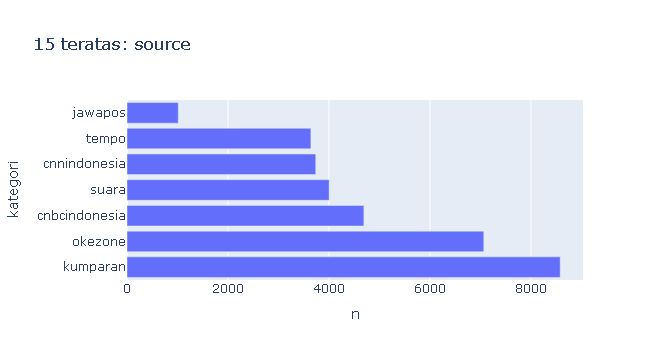

In [4]:
t = duckdb.sql(f"""SELECT "{C1}" AS kategori, count(*) AS n FROM '{P}'
                   WHERE "{C1}" IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 15""").pl()
save(px.bar(t, x="n", y="kategori", orientation="h", title=f"15 teratas: {C1}"), "03_top_kategori")

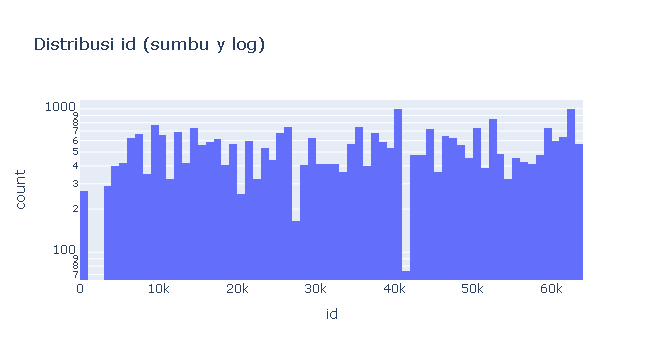

In [5]:
h = lf.select(N1).drop_nulls().collect()
h = h.sample(min(200_000, h.height), seed=42)
save(px.histogram(h, x=N1, nbins=80, log_y=True, title=f"Distribusi {N1} (sumbu y log)"), "04_distribusi")

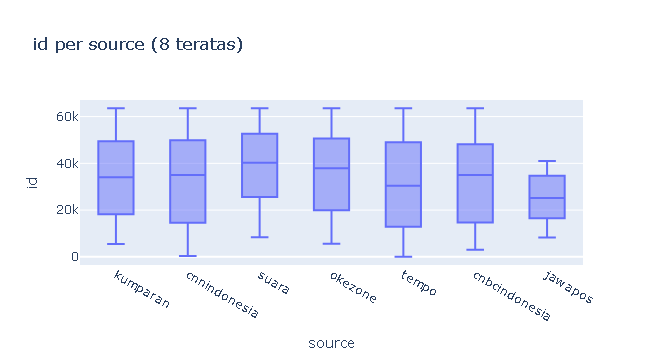

In [6]:
top8 = t["kategori"].head(8).to_list()
b = (lf.filter(pl.col(C1).is_in(top8)).select(C1, N1).drop_nulls().collect())
b = b.sample(min(100_000, b.height), seed=42)
save(px.box(b, x=C1, y=N1, title=f"{N1} per {C1} (8 teratas)"), "05_box_kategori")

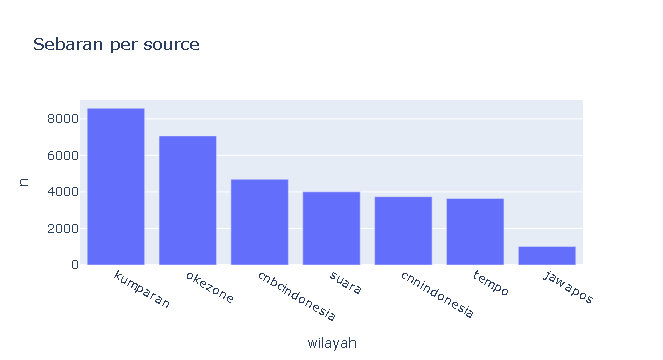

In [7]:
if LAT and LON:
    g = lf.select(LAT, LON).drop_nulls().collect()
    g = g.sample(min(50_000, g.height), seed=42)
    try:
        fig = px.scatter_map(g, lat=LAT, lon=LON, zoom=3, opacity=0.4, title="Sebaran lokasi")
    except AttributeError:
        fig = px.scatter_mapbox(g, lat=LAT, lon=LON, zoom=3, opacity=0.4,
                                mapbox_style="open-street-map", title="Sebaran lokasi")
else:
    s = duckdb.sql(f"""SELECT "{C2}" AS wilayah, count(*) AS n FROM '{P}'
                       WHERE "{C2}" IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 20""").pl()
    fig = px.bar(s, x="wilayah", y="n", title=f"Sebaran per {C2}")
save(fig, "06_spasial")

In [8]:
print("Total baris:", lf.select(pl.len()).collect().item())
if DATE_COL:
    print("\nBulan terpadat:\n", d.sort("n", descending=True).head(3))
    print("\nBulan tersepi:\n", d.sort("n").head(3))
print("\nTop kategori:\n", t.with_columns((pl.col("n")/pl.col("n").sum()*100).round(1).alias("persen_top15")).head(5))
if N1:
    print("\nStatistik", N1, ":\n", lf.select(pl.col(N1).describe()).collect() if False else lf.select(N1).collect().describe())
if len(NUM_COLS) > 1:
    print("\nKorelasi:\n", lf.select(NUM_COLS[:8]).collect().corr())

Total baris: 32735

Bulan terpadat:
 shape: (3, 2)
┌─────────────────────┬───────┐
│ bulan               ┆ n     │
│ ---                 ┆ ---   │
│ datetime[μs]        ┆ i64   │
╞═════════════════════╪═══════╡
│ 2023-03-01 00:00:00 ┆ 21223 │
│ 2023-04-01 00:00:00 ┆ 11511 │
│ 2018-08-01 00:00:00 ┆ 1     │
└─────────────────────┴───────┘

Bulan tersepi:
 shape: (3, 2)
┌─────────────────────┬───────┐
│ bulan               ┆ n     │
│ ---                 ┆ ---   │
│ datetime[μs]        ┆ i64   │
╞═════════════════════╪═══════╡
│ 2018-08-01 00:00:00 ┆ 1     │
│ 2023-04-01 00:00:00 ┆ 11511 │
│ 2023-03-01 00:00:00 ┆ 21223 │
└─────────────────────┴───────┘

Top kategori:
 shape: (5, 3)
┌───────────────┬──────┬──────────────┐
│ kategori      ┆ n    ┆ persen_top15 │
│ ---           ┆ ---  ┆ ---          │
│ str           ┆ i64  ┆ f64          │
╞═══════════════╪══════╪══════════════╡
│ kumparan      ┆ 8579 ┆ 26.2         │
│ okezone       ┆ 7066 ┆ 21.6         │
│ cnbcindonesia ┆ 4691 ┆ 14.3   